In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bumba5341/advertisingcsv")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'advertisingcsv' dataset.
Path to dataset files: /kaggle/input/advertisingcsv


Dataset Head:


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9



Mean Squared Error: 3.17
Root Mean Squared Error: 1.78
R2 Score: 0.90

Feature Impact on Sales:


,Feature,Coefficient
0,TV,0.044730
1,Radio,0.189195
2,Newspaper,0.002761


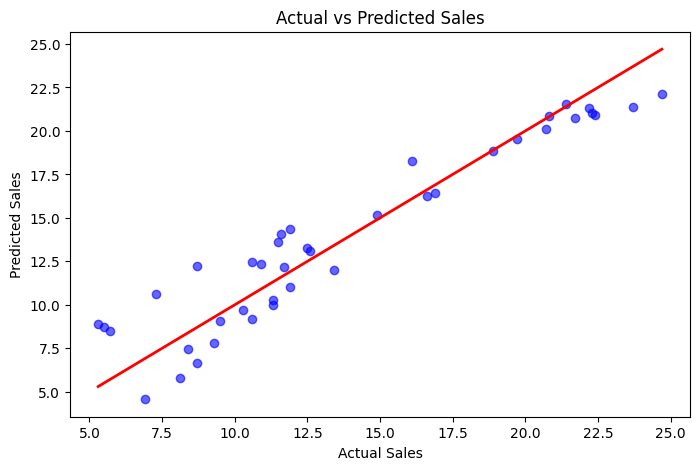


Predicted Sales for Sample Input: 20.61


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset from the downloaded local path
csv_file = os.path.join(path, "Advertising.csv")
df = pd.read_csv(csv_file)

if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

df = df.dropna()
df = df.drop_duplicates()

print("Dataset Head:")
display(df.head())

X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\nMean Squared Error: {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f}")
print(f"R2 Score: {r2:.2f}")

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})
print("\nFeature Impact on Sales:")
display(coefficients)

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color="blue", alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", lw=2)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()

sample_input = pd.DataFrame([[230.1, 37.8, 69.2]], columns=["TV", "Radio", "Newspaper"])
predicted_sales = model.predict(sample_input)
print(f"\nPredicted Sales for Sample Input: {predicted_sales[0]:.2f}")

In [4]:
from sklearn.ensemble import RandomForestRegressor

# 1. Train the Random Forest model
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

# 2. Predict and Evaluate
y_pred_rf = rf_model.predict(X_test)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, y_pred_rf)

print("--- Random Forest Evaluation ---")
print(f"Root Mean Squared Error (RMSE): {rf_rmse:.2f}")
print(f"R2 Score: {rf_r2:.2f}")

--- Random Forest Evaluation ---
Root Mean Squared Error (RMSE): 0.77
R2 Score: 0.98
